# 03 — Replicating 2018 and 2025: synthetic control, then DiD

Next step 4 in `CONTRIBUTING.md` (decisions D19, D20). Roles of series come from D18 (`data/processed/treatment_roles.csv`, notebook 02).
- Synthetic control per treated series [M1, M2], donors = usable controls at the finest level (no parent–child overlap).
- Inference: in-space permutation over the donors (ratio of post/pre RMSPE) [M1].
- Falsification: the 11 over-quota-only dairy and egg series of 2025 (expected effect ≈ 0).
- Robustness: 2×2 and event-study difference-in-differences with series and month fixed effects, SE clustered by series [M3].
- `rho` = effect / tariff rate = pass-through × share of US-origin tariffed goods in the series. It is **not** a pass-through rate on its own.

In [1]:
import sys
from pathlib import Path
root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(root / "src"), str(root / "src" / "causal")]
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import synth as S
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 70)

roles = pd.read_csv(root / "data/processed/treatment_roles.csv")
cat = pd.read_csv(root / "data/processed/cpi_food_catalog.csv")
parent = dict(zip(cat["product"], cat["parent"]))
tmap = pd.read_csv(root / "data/reference/tariff_cpi_map.csv").set_index(["event_id", "cpi_product"])
wide = S.cpi_wide()

def groups(ev):
    u = roles[(roles.event_id == ev) & roles.usable]
    return (u[u.role == "treated"]["product"].tolist(), u[u.role == "placebo"]["product"].tolist(),
            S.finest(u[u.role == "control"]["product"].tolist(), parent))

for ev, ep in S.EPISODES.items():
    tr, pl, don = groups(ev)
    print(ev, {k: (str(a), str(b)) for k, (a, b) in ep.windows(wide.index.max()).items()},
          f"treated={len(tr)} placebo={len(pl)} donors={len(don)}")

CA2018 {'pre': ('2013-07', '2018-06'), 'during': ('2018-07', '2019-05'), 'after': ('2019-06', '2020-02')} treated=10 placebo=0 donors=52
CA2025 {'pre': ('2020-03', '2025-02'), 'during': ('2025-03', '2025-08'), 'after': ('2025-09', '2026-08')} treated=22 placebo=11 donors=22


## 1. Choice of specification (criterion fixed before looking at effects: pre-period fit)

`t0`: cumulative log change since the last pre-tariff month. `main`: seasonality removed and centred on the pre-window mean (D19).

In [2]:
results, objs, fit = {}, {}, []
for ev, ep in S.EPISODES.items():
    tr, pl, don = groups(ev)
    for spec in ["t0", "main"]:
        res, obj = S.run_episode(wide, ep, tr, don, pl, spec)
        results[(ev, spec)], objs[(ev, spec)] = res, obj
        fit.append({"event_id": ev, "spec": spec,
                    "median_pre_rmspe_treated": res[res.group == "treated"].pre_rmspe.median(),
                    "median_pre_rmspe_donors": np.median([r["pre_rmspe"] for r in obj["perm"].values()])})
pd.DataFrame(fit).round(2)

,event_id,spec,median_pre_rmspe_treated,median_pre_rmspe_donors
0,CA2018,t0,1.32,1.49
1,CA2018,main,1.07,1.09
2,CA2025,t0,2.87,2.91
3,CA2025,main,2.11,1.88


## 2. Synthetic control results (main specification)

In [3]:
main = pd.concat([results[(ev, "main")] for ev in S.EPISODES])
main.to_csv(root / "data/processed/sc_results.csv", index=False)
main[["event_id", "group", "series", "effect_during", "effect_end", "effect_after", "pre_rmspe", "p_value", "rho_during"]].round(3)

,event_id,group,series,effect_during,effect_end,effect_after,pre_rmspe,p_value,rho_during
0,CA2018,treated,Other dairy products,1.736,3.137,1.734,0.720,0.132,0.174
1,CA2018,treated,Other bakery products,-2.072,-4.628,-2.095,0.834,0.283,-0.207
2,CA2018,treated,Fruit juices,-3.135,-5.492,-2.805,1.535,0.396,-0.313
3,CA2018,treated,"Jam, jelly and other preserves (2013=100)",-2.690,-3.660,-5.434,0.743,0.113,-0.269
4,CA2018,treated,Confectionery,-1.798,-2.667,-1.388,0.900,0.321,-0.180
5,CA2018,treated,Roasted or ground coffee (2013=100),-2.107,-2.320,-2.263,1.158,0.509,-0.211
6,CA2018,treated,Fermented or pickled vegetables (2013=100),-4.009,-5.469,-5.192,1.542,0.283,-0.401
7,CA2018,treated,"Sauces, condiments and dips (2013=100)",-0.894,-4.637,-3.659,1.309,0.623,-0.089
8,CA2018,treated,Soup,-1.748,6.666,0.454,1.527,0.151,-0.175
9,CA2018,treated,Non-alcoholic beverages,-1.169,-1.662,1.220,0.980,0.491,-0.117


In [4]:
summary = (main.groupby(["event_id", "group"])
           .agg(n=("series", "size"), mean_during=("effect_during", "mean"), median_during=("effect_during", "median"),
                mean_after=("effect_after", "mean"), n_p_lt_010=("p_value", lambda p: (p < 0.10).sum()),
                n_p_lt_005=("p_value", lambda p: (p < 0.05).sum())))
summary.round(2)

n  mean_during  median_during  mean_after  n_p_lt_010  n_p_lt_005
event_id group                                                                      
CA2018   treated  10        -1.79          -1.94       -1.94           0           0
CA2025   placebo  11        -2.38          -2.19       -4.06           1           1
         treated  22         1.05          -0.16       -0.16           2           1

## 3. Difference-in-differences (robustness, M3)

Average effect over the tariff months, treated series vs donors, series and month fixed effects.
`mde_80pct_power` = 2.8 × SE: the smallest average effect this design detects with 80% power at the 5% level.

In [5]:
did = []
for ev, ep in S.EPISODES.items():
    tr, pl, don = groups(ev)
    Y = objs[(ev, "main")]["Y"]
    did.append({**S.did_2x2(Y, tr, don, ep), "sample": "all treated"})
    if ev == "CA2025":
        did.append({**S.did_2x2(Y, pl, don, ep), "sample": "placebo series as 'treated'"})
did = pd.DataFrame(did)
did["se"] = (did.hi - did.lo) / (2 * 1.96)
did["mde_80pct_power"] = 2.8 * did.se
did.round(2)

,event_id,did,lo,hi,p,n_treated,n_controls,sample,se,mde_80pct_power
0,CA2018,-1.88,-4.42,0.65,0.15,10,52,all treated,1.30,3.63
1,CA2025,2.09,-1.61,5.80,0.27,22,22,all treated,1.89,5.29
2,CA2025,-2.03,-4.91,0.86,0.17,11,22,placebo series as 'treated',1.47,4.12


## 4. Sensitivity

In [6]:
sens = []
def add(ev, label, drop):
    ep = S.EPISODES[ev]; tr, pl, don = groups(ev)
    keep = [t for t in tr if t not in drop]
    d = S.did_2x2(objs[(ev, "main")]["Y"], keep, don, ep)
    m = main[(main.event_id == ev) & (main.group == "treated") & main.series.isin(keep)].effect_during.mean()
    sens.append({"event_id": ev, "variant": label, "n_treated": len(keep), "sc_mean": m, "did": d["did"], "lo": d["lo"], "hi": d["hi"]})

conf = lambda ev, s: tmap.confidence.get((ev, s), "inherited")
add("CA2018", "all treated", [])
add("CA2018", "without Other dairy products (broad series, D18 check)", ["Other dairy products"])
add("CA2025", "all treated", [])
add("CA2025", "without coffee and confectionery (world coffee and cocoa prices)",
    ["Roasted or ground coffee (2013=100)", "Confectionery"])
add("CA2025", "high-confidence mappings only", [s for s in groups("CA2025")[0] if conf("CA2025", s) != "high"])
pd.DataFrame(sens).round(2)

,event_id,variant,n_treated,sc_mean,did,lo,hi
0,CA2018,all treated,10,-1.79,-1.88,-4.42,0.65
1,CA2018,"without Other dairy products (broad series, D18 check)",9,-2.18,-1.82,-4.49,0.85
2,CA2025,all treated,22,1.05,2.09,-1.61,5.80
3,CA2025,without coffee and confectionery (world coffee and cocoa prices),20,0.05,0.98,-2.33,4.30
4,CA2025,high-confidence mappings only,16,1.92,3.97,-0.06,8.01


## 5. Event studies (DiD by month relative to the tariff, reference = month −1)

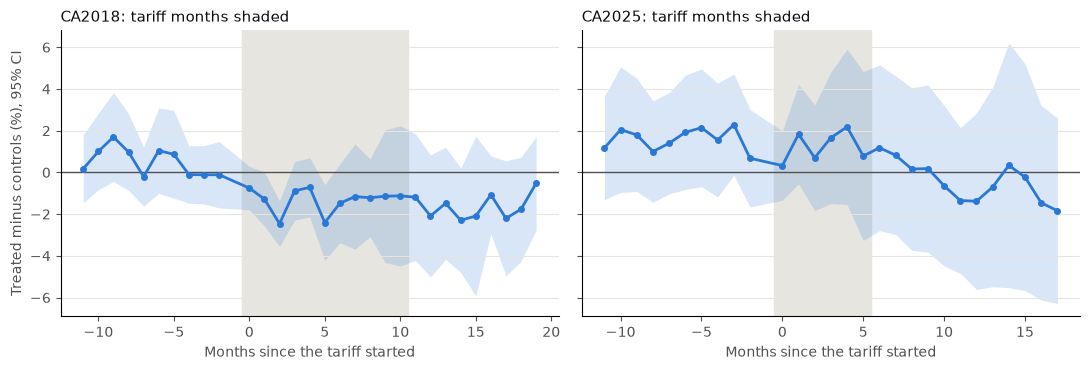

CA2018                   CA2025                  
            coef    lo    hi     p   coef    lo    hi     p
rel_month                                                  
-12         0.57 -1.81  2.95  0.64  -1.36 -6.19  3.46  0.58
-11         0.17 -1.46  1.80  0.84   1.17 -1.31  3.66  0.35
-10         1.00 -0.83  2.83  0.28   2.05 -0.96  5.05  0.18
-9          1.70 -0.43  3.83  0.12   1.80 -0.92  4.51  0.19
-8          0.97 -0.86  2.81  0.30   1.00 -1.43  3.44  0.42
-7         -0.21 -1.62  1.21  0.78   1.40 -1.03  3.83  0.26
-6          1.04 -1.00  3.09  0.32   1.92 -0.82  4.66  0.17
-5          0.87 -1.23  2.97  0.42   2.14 -0.68  4.96  0.14
-4         -0.10 -1.48  1.27  0.88   1.55 -1.17  4.28  0.26
-3         -0.11 -1.51  1.29  0.87   2.29 -0.14  4.72  0.06
-2         -0.11 -1.70  1.48  0.89   0.68 -1.66  3.02  0.57
 0         -0.75 -1.79  0.29  0.16   0.33 -1.33  1.98  0.70
 1         -1.28 -2.57  0.01  0.05   1.83 -0.55  4.21  0.13
 2         -2.46 -3.54 -1.37  0.00   0.70 -1.83  3.23  0.59
 3         -0.89 -2.29  0.51  0.21   1.66 -1.49  4.81  0.30
 4         -0.72 -2.14  0.70  0.32   2.18 -1.55  5.90  0.25
 5         -2.41 -4.22 -0.59  0.01   0.78 -3.26  4.83  0.70
 6         -1.48 -3.37  0.41  0.13   1.18 -2.79  5.16  0.56
 7         -1.16 -3.68  1.36  0.37   0.82 -2.97  4.62  0.67
 8         -1.22 -3.08  0.64  0.20   0.16 -3.74  4.06  0.94
 9         -1.14 -4.32  2.04  0.48   0.18 -3.83  4.19  0.93
 10        -1.13 -4.49  2.24  0.51  -0.64 -4.49  3.20  0.74
 11        -1.19 -4.22  1.84  0.44  -1.35 -4.84  2.14  0.45
 12        -2.09 -5.02  0.84  0.16  -1.38 -5.61  2.84  0.52
 13        -1.48 -4.17  1.21  0.28  -0.70 -5.48  4.07  0.77
 14        -2.29 -4.80  0.21  0.07   0.34 -5.53  6.20  0.91
 15        -2.09 -5.93  1.74  0.28  -0.23 -5.66  5.21  0.93
 16        -1.07 -2.93  0.79  0.26  -1.46 -6.12  3.21  0.54
 17        -2.21 -4.96  0.55  0.12  -1.84 -6.28  2.61  0.42
 18        -1.77 -4.26  0.73  0.17    NaN   NaN   NaN   NaN
 19        -0.52 -2.76  1.72  0.65    NaN   NaN   NaN   NaN

In [7]:
ES = {}
for ev, ep in S.EPISODES.items():
    tr, pl, don = groups(ev)
    ES[ev] = S.event_study(objs[(ev, "main")]["Y"], tr, don, ep)

BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e0"
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (ev, es) in zip(axes, ES.items()):
    ep = S.EPISODES[ev]
    es = es[es.rel_month > -12]
    ax.axhline(0, color=MUTED, lw=1)
    ax.axvspan(-0.5, (ep.last_month - ep.first_month).n + 0.5, color=GRID, zorder=0)
    ax.fill_between(es.rel_month, es.lo, es.hi, color=BLUE, alpha=0.18, lw=0)
    ax.plot(es.rel_month, es.coef, color=BLUE, lw=2, marker="o", ms=4)
    ax.set_title(f"{ev}: tariff months shaded", color=INK, fontsize=11, loc="left")
    ax.set_xlabel("Months since the tariff started", color=MUTED)
    ax.tick_params(colors=MUTED)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(axis="y", color=GRID, lw=0.8)
axes[0].set_ylabel("Treated minus controls (%), 95% CI", color=MUTED)
plt.tight_layout(); plt.show()
pd.concat({ev: es.set_index("rel_month")[["coef", "lo", "hi", "p"]] for ev, es in ES.items()}, axis=1).round(2)

## 6. 2025: treated vs placebo series, effect during the tariff months

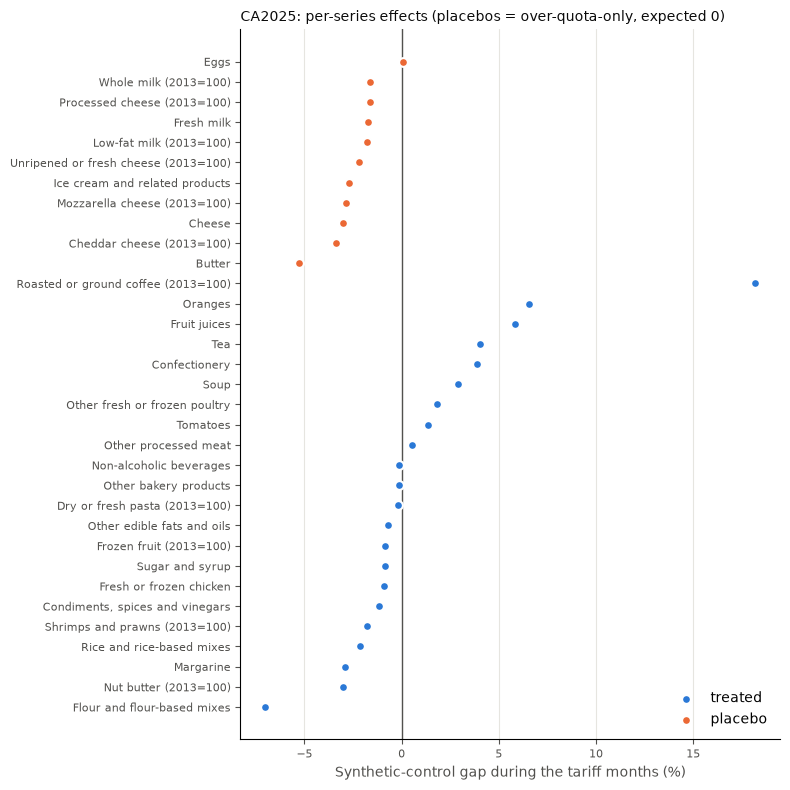

In [8]:
d = main[main.event_id == "CA2025"].sort_values("effect_during")
fig, ax = plt.subplots(figsize=(8, 8))
for g, col in [("treated", BLUE), ("placebo", ORANGE)]:
    s = d[d.group == g]
    ax.scatter(s.effect_during, s.series, color=col, s=40, label=g, edgecolor="white", linewidth=1.5, zorder=3)
ax.axvline(0, color=MUTED, lw=1)
ax.set_xlabel("Synthetic-control gap during the tariff months (%)", color=MUTED)
ax.tick_params(colors=MUTED, labelsize=8)
ax.grid(axis="x", color=GRID, lw=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc="lower right")
ax.set_title("CA2025: per-series effects (placebos = over-quota-only, expected 0)", color=INK, fontsize=10, loc="left")
plt.tight_layout(); plt.show()

## 7. Findings

Written up in D20 (decision log).